## V5589 Sgr Spectral Index

In [3]:
#imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import scipy

import astropy
from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [24]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

### Importing the data and putting it in a large dataframe

In [19]:
data = ([56040.4,	1,	33,	0.032,	0.025,	1.00E-10,	0.05],
    [56069.0,	'A',	225.3,	13.80,	2.000,	1.00E-10,	0.05],
    [56084.4,	2,	5,	1.089,	0.028,	1.00E-10,	0.05],
    [56084.4,	2,	6.8,	1.381,	0.025,	1.00E-10,	0.05],
    [56092.2,	3,	13.3,	3.523,	0.042,	1.00E-10,	0.05],
    [56092.2,	3,	16,	3.98,	0.049,	1.00E-10,	0.05],
    [56092.2,	3,	28.2,	5.727,	0.098,	1.00E-10,	0.05],
    [56092.2,	3,	36.5,	5.961,	0.139,	1.00E-10,	0.05],
    [56100.3,	4,	2.5,	3.094,	0.037,	1.00E-10,	0.05],
    [56100.3,	4,	3.5,	3.201,	0.030,	1.00E-10,	0.05],
    [56100.3,	4,	5,	3.423,	0.023,	1.00E-10,	0.05],
    [56100.3,	4,	6.8,	3.629,	0.025,	1.00E-10,	0.05],
    [56100.3,	4,	8.5,	3.683,	0.052,	1.00E-10,	0.05],
    [56100.3,	4,	11.4,	3.779,	0.071,	1.00E-10,	0.05],
    [56117.9,	'B',	225.5,	0.000,	0.068,	1.00E-10,	0.05],
    [56119.1,	5,	1.35,	1.68,	0.120,	1.00E-10,	0.05],
    [56119.1,	5,	1.84,	1.391,	0.066,	1.00E-10,	0.05],
    [56119.1,	5,	4.74,	1.907,	0.027,	1.00E-10,	0.05],
    [56119.1,	5,	7.59,	1.921,	0.023,	1.00E-10,	0.05],
    [56128.3,	6,	17.5,	1.374,	0.091,	1.00E-10,	0.05],
    [56128.3,	6,	27.5,	1.438,	0.143,	1.00E-10,	0.05],
    [56128.3,	6,	36.5,	1.136,	0.194,	1.00E-10,	0.05],
    [56148.0,	7,	1.2555,	0.340,	0.071,	1.00E-10,	0.05],
    [56148.0,	7,	1.7715,	0.560,	0.072,	1.00E-10,	0.05],
    [56148.0,	7,	4.74,	0.521,	0.033,	1.00E-10,	0.05],
    [56148.0,	7,	7.59,	0.528,	0.025,	1.00E-10,	0.05],
    [56148.0,	7,	8.53,	0.556,	0.031,	1.00E-10,	0.05],
    [56148.0,	7,	11.38,	0.571,	0.060,	1.00E-10,	0.05],
    [56150.2,	8,	13.3,	0.495,	0.042,	1.00E-10,	0.05],
    [56150.2,	8,	17.45,	0.38,	0.049,	1.00E-10,	0.05],
    [56150.2,	8,	27.5,	0.469,	0.078,	1.00E-10,	0.05],
    [56150.2,	8,	36.5,	0.39,	0.086,	1.00E-10,	0.05],
    [56151.3,	8,	1.25,	0,	0.091,	1.00E-10,	0.05],
    [56151.3,	8,	1.80,	0.497,	0.088,	1.00E-10,	0.05],
    [56151.3,	8,	4.549,	0.502,	0.034,	1.00E-10,	0.05],
    [56151.3,	8,	7.399,	0.469,	0.025,	1.00E-10,	0.05],
    [56151.3,	8,	8.51,	0.443,	0.021,	1.00E-10,	0.05],
    [56151.3,	8,	11.34,	0.418,	0.035,	1.00E-10,	0.05],
    
    [56167.0,	9,	1.36,	0.244,	0.049,	1.00E-10,	0.05],
    [56167.0,	9,	1.78,	0.431,	0.048,	1.00E-10,	0.05],

    [56167.0,	9,	4.608,	0.347,	0.028,	1.00E-10,	0.05],
    [56167.0,	9,	7.458,	0.292,	0.016,	1.00E-10,	0.05],
    [56167.0,	9,	8.5,	0.289,	0.018,	1.00E-10,	0.05],
    [56167.0,	9,	11.4,	0.368,	0.031,	1.00E-10,	0.05],

    [56174.2,	10,	13.3,	0.188,	0.019,	1.00E-10,	0.05],
    [56174.2,	10,	17.45,	0.110,	0.029,	1.00E-10,	0.05],
    [56174.2,	10,	27.5,	0.106,	0.027,	1.00E-10,	0.05],
    [56174.2,	10,	36.5,	0.365,	0.131,	1.00E-10,	0.05],
    [56177.9,	11,	1.33,	0.225,	0.044,	1.00E-10,	0.05],
    [56177.9,	11,	1.77,	0.201,	0.042,	1.00E-10,	0.05],
    [56231.0,	12,	13.3,	0.035,	0.021,	1.00E-10,	0.05],
    [56231.0,	12,	17.4,	0.043,	0.027,	1.00E-10,	0.05],
    [56231.0,	12,	27.5,	0.060,	0.044,	1.00E-10,	0.05],
    [56231.0,	12,	36.5,	0.044,	0.052,	1.00E-10,	0.05],
    [56270.8,	13,	1.2555,	0,	0.083,	1.00E-10,	0.05],
    [56270.8,	13,	1.7395,	0,	0.084,	1.00E-10,	0.05],
    [56270.8,	13,	4.549,	0,	0.021,	1.00E-10,	0.05],
    [56270.8,	13,	7.399,	0,	0.016,	1.00E-10,	0.05],
    [56270.8,	13,	8.519,	0,	0.025,	1.00E-10,	0.05],
    [56270.8,	13,	11.399,	0,	0.030,	1.00E-10,	0.05],
    [56284.6,	14,	13.299,	0,	0.029,	1.00E-10,	0.05],
    [56284.6,	14,	17.449,	0,	0.035,	1.00E-10,	0.05],
    [56284.6,	14,	13.30,	0.047,	0.022,	1.00E-10,	0.05],
    [56284.6,	14,	17.45,	0.049,	0.026,	1.00E-10,	0.05],
    [56284.6,	14,	27.50,	0.036,	0.050,	1.00E-10,	0.05],
    [56284.6,	14,	36.50,	0.020,	0.068,	1.00E-10,	0.05],
    [56297.7,	15,	1.26,	0.0504,	0.102,	1.00E-10,	0.05],
    [56297.7,	15,	1.74,	-0.00249,	0.068,	1.00E-10,	0.05],
    [56297.7,	15,	4.55,	0.0328,	0.033,	1.00E-10,	0.05],
    [56297.7,	15,	7.399,	0.0288,	0.023,	1.00E-10,	0.05],
    [56297.7,	15,	8.52,	0.0286,	0.018,	1.00E-10,	0.05],
    [56297.7,	15,	11.4,	0.0413,	0.023,	1.00E-10,	0.05],
    [56347.7,	16,	1.26,	0.346,	0.503,	1.00E-10,	0.05],
    [56347.7,	16,	1.74,	-0.0272,	0.368,	1.00E-10,	0.05],
    [56347.7,	16,	4.55,	-0.232,	0.114,	1.00E-10,	0.05],
    [56347.7,	16,	7.399,	-0.00948,	0.160,	1.00E-10,	0.05],
    [56347.7,	16,	8.52,	0.465,	0.201,	1.00E-10,	0.05],
    [56347.7,	16,	11.4,	-0.0358,	0.301,	1.00E-10,	0.05],
    [56358.6,	17,	13.22,	0.025,	0.027,	1.00E-10,	0.05],
    [56358.6,	17,	17.45,	0.009,	0.025,	1.00E-10,	0.05],
    [56358.6,	17,	27.50,	0.046,	0.049,	1.00E-10,	0.05],
    [56358.6,	17,	36.50,	0.120,	0.062,	1.00E-10,	0.05],
    [56369.6,	17,	13.3,	-0.0319,	0.023,	1.00E-10,	0.05],
    [56369.6,	17,	17.4,	0.0240,	0.029,	1.00E-10,	0.05],
    [56369.6,	17,	27.5,	0.113,	0.065,	1.00E-10,	0.05],
    [56369.6,	17,	36.5,	0.0109,	0.083,	1.00E-10,	0.05],
    [56441.4,	18,	1.26,	0.0811,	0.396,	1.00E-10,	0.05],
    [56441.4,	18,	1.74,	-0.202,	0.326,	1.00E-10,	0.05],
    [56441.4,	18,	4.55,	0.0437,	0.033,	1.00E-10,	0.05],
    [56441.4,	18,	7.399,	-0.0098,	0.021,	1.00E-10,	0.05],
    [56441.4,	18,	8.52,	-0.00263,	0.018,	1.00E-10,	0.05],
    [56441.4,	18,	11.4,	-0.0266,	0.019,	1.00E-10,	0.05],
    [56446.2,	18,	13.3,	-0.0169,	0.024,	1.00E-10,	0.05],
    [56446.2,	18,	17.4,	0.0260,	0.029,	1.00E-10,	0.05],
    [56446.2,	18,	27.5,	0.112,	0.077,	1.00E-10,	0.05],
    [56446.2,	18,	36.5,	-0.0663,	0.095,	1.00E-10,	0.05],
    [56526.7,	19,	1.26,	-0.571,	0.276,	1.00E-10,	0.05],
    [56526.7,	19,	1.74,	-0.348,	0.169,	1.00E-10,	0.05],
    [56526.7,	19,	4.55,	-0.00306,	0.028,	1.00E-10,	0.05],
    [56526.7,	19,	7.40,	-0.0045,	0.019,	1.00E-10,	0.05],
    [56526.7,	19,	8.52,	0.00449,	0.022,	1.00E-10,	0.05],
    [56526.7,	19,	11.4,	-0.0051,	0.024,	1.00E-10,	0.05],
    [56530.7,	19,	13.3,	-0.00734,	0.031,	1.00E-10,	0.05],
    [56530.7,	19,	17.4,	-0.00912,	0.053,	1.00E-10,	0.05],
    [56530.7,	19,	27.5,	0.0271,	0.011,	1.00E-10,	0.05],
    [56530.7,	19,	36.5,	0.110,	0.110,	1.00E-10,	0.05],
       )

df =  pd.DataFrame(data, columns = ["MJD",	"Epoch",	"Freq",	"Flux",	"error","RM", "systematics"])

In [20]:
#MJD of discovery: 56038.0 
mjd = df['MJD']
freq = df['Freq']
flux = df['Flux']
err = df['error']

In [21]:


def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

day = np.array(MJD_to_date(mjd,56038.0 ))


In [22]:
#Split into dates 
C1 = np.logical_and(day>= 2.0, day<= 3.0)          #2.4
C2 = np.logical_and(day>= 30.0, day<= 32.0)        #31
C3 = np.logical_and(day>= 45.0, day<= 50.0)        #46.4
C4 = np.logical_and(day>= 51.0, day<= 55.0)        #54.2
C5 = np.logical_and(day>= 61.0, day<= 65.0)        #62.3
C6 = np.logical_and(day>= 75.0, day<= 80.0)        #79.9
C7 = np.logical_and(day>= 80.0, day<= 85.0)        #81.1

C8 = np.logical_and(day>= 89.0, day<= 91.0)         #90.3
C9 = np.logical_and(day>= 100, day<= 111.0)         #110
C10 = np.logical_and(day>= 112, day<= 115)          #113.3
C11 = np.logical_and(day>= 128, day<= 130)          #129
C12 = np.logical_and(day>= 134, day<= 137)          #136.2
C13 = np.logical_and(day>= 138, day<= 140)          #139.9
C14 = np.logical_and(day>= 190, day<= 195)          #193

C15 = np.logical_and(day>= 230, day<= 235)         #232.8
C16 = np.logical_and(day>= 240, day<= 250)         #246.6
C17 = np.logical_and(day>= 250, day<= 261)          #259.7
C18 = np.logical_and(day>= 300, day<= 310)          #309.7
C19 = np.logical_and(day>= 311, day<= 324)          #320.6
C20 = np.logical_and(day>= 330, day<= 335)          #331.6
C21 = np.logical_and(day>= 400, day<= 405)          #403.4

C22 = np.logical_and(day>= 406, day<= 410)          #408.2
C23 = np.logical_and(day>= 480, day<= 490)          #448.7
C24 = np.logical_and(day>= 491, day<= 495)          #492.7


In [23]:
D1  = np.where(np.logical_and(C1, flux > 3*err))    
D1N = np.where(np.logical_and(C1, flux < 3*err))    #Non detection

D2  = np.where(np.logical_and(C2, flux > 3*err))    
D2N = np.where(np.logical_and(C2, flux < 3*err))

D3  = np.where(np.logical_and(C3, flux > 3*err))    
D3N = np.where(np.logical_and(C3, flux < 3*err))

D4  = np.where(np.logical_and(C4, flux > 3*err))    
D4N = np.where(np.logical_and(C4, flux < 3*err))

D5  = np.where(np.logical_and(C5, flux > 3*err))    
D5N = np.where(np.logical_and(C5, flux < 3*err))

D6  = np.where(np.logical_and(C6, flux > 3*err))    
D6N = np.where(np.logical_and(C6, flux < 3*err))    #Non detection

D7  = np.where(np.logical_and(C7, flux > 3*err))    
D7N = np.where(np.logical_and(C7, flux < 3*err))

D8  = np.where(np.logical_and(C8, flux > 3*err))    
D8N = np.where(np.logical_and(C8, flux < 3*err))

D9  = np.where(np.logical_and(C9, flux > 3*err))    
D9N = np.where(np.logical_and(C9, flux < 3*err))

D10  = np.where(np.logical_and(C10, flux > 3*err))    
D10N = np.where(np.logical_and(C10, flux < 3*err))

D11  = np.where(np.logical_and(C11, flux > 3*err))    
D11N = np.where(np.logical_and(C11, flux < 3*err))    #Non detection

D12  = np.where(np.logical_and(C12, flux > 3*err))    
D12N = np.where(np.logical_and(C12, flux < 3*err))

D13  = np.where(np.logical_and(C13, flux > 3*err))    
D13N = np.where(np.logical_and(C13, flux < 3*err))

D14  = np.where(np.logical_and(C14, flux > 3*err))    
D14N = np.where(np.logical_and(C14, flux < 3*err))

D15  = np.where(np.logical_and(C15, flux > 3*err))    
D15N = np.where(np.logical_and(C15, flux < 3*err))

D16  = np.where(np.logical_and(C16, flux > 3*err))    
D16N = np.where(np.logical_and(C16, flux < 3*err))    #Non detection

D17  = np.where(np.logical_and(C17, flux > 3*err))    
D17N = np.where(np.logical_and(C17, flux < 3*err))

D18  = np.where(np.logical_and(C18, flux > 3*err))    
D18N = np.where(np.logical_and(C18, flux < 3*err))

D19  = np.where(np.logical_and(C19, flux > 3*err))    
D19N = np.where(np.logical_and(C19, flux < 3*err))

D20  = np.where(np.logical_and(C20, flux > 3*err))    
D20N = np.where(np.logical_and(C20, flux < 3*err))

D21  = np.where(np.logical_and(C21, flux > 3*err))    
D21N = np.where(np.logical_and(C21, flux < 3*err))

D22  = np.where(np.logical_and(C22, flux > 3*err))    
D22N = np.where(np.logical_and(C22, flux < 3*err))

D23  = np.where(np.logical_and(C23, flux > 3*err))    
D23N = np.where(np.logical_and(C23, flux < 3*err))

D24  = np.where(np.logical_and(C24, flux > 3*err))    
D24N = np.where(np.logical_and(C24, flux < 3*err))

In [26]:
freq_1 = np.ravel([freq[i] for i in D1])
flux_1 = np.ravel([flux[i] for i in D1])
err_1  = np.ravel([err[i] for i in D1])
date_1 = np.ravel([day[i] for i in D1])

nflux_1 = np.ravel([flux[i] + err[i]*3  for i in D1N])
nfreq_1 = np.ravel([freq[i] for i in D1N])
ndate_1 = np.ravel([day[i] for i in D1N])
####################################################

freq_2 = np.ravel([freq[i] for i in D2])
flux_2 = np.ravel([flux[i] for i in D2])
err_2  = np.ravel([err[i] for i in D2])
date_2 = np.ravel([day[i] for i in D2])

nflux_2 = np.ravel([flux[i] + err[i]*3  for i in D2N])
nfreq_2 = np.ravel([freq[i] for i in D2N])
ndate_2 = np.ravel([day[i] for i in D2N])
####################################################

freq_3 = np.ravel([freq[i] for i in D3])
flux_3 = np.ravel([flux[i] for i in D3])
err_3  = np.ravel([err[i] for i in D3])
date_3 = np.ravel([day[i] for i in D3])

nflux_3 = np.ravel([flux[i] + err[i]*3  for i in D3N])
nfreq_3 = np.ravel([freq[i] for i in D3N])
ndate_3 = np.ravel([day[i] for i in D3N])
####################################################

freq_4 = np.ravel([freq[i] for i in D4])
flux_4 = np.ravel([flux[i] for i in D4])
err_4  = np.ravel([err[i] for i in D4])
date_4 = np.ravel([day[i] for i in D4])

nflux_4 = np.ravel([flux[i] + err[i]*3  for i in D4N])
nfreq_4 = np.ravel([freq[i] for i in D4N])
ndate_4 = np.ravel([day[i] for i in D4N])
####################################################

freq_5 = np.ravel([freq[i] for i in D5])
flux_5 = np.ravel([flux[i] for i in D5])
err_5  = np.ravel([err[i] for i in D5])
date_5 = np.ravel([day[i] for i in D5])

nflux_5 = np.ravel([flux[i] + err[i]*3  for i in D5N])
nfreq_5 = np.ravel([freq[i] for i in D5N])
ndate_5 = np.ravel([day[i] for i in D5N])
####################################################

freq_6 = np.ravel([freq[i] for i in D6])
flux_6 = np.ravel([flux[i] for i in D6])
err_6  = np.ravel([err[i] for i in D6])
date_6 = np.ravel([day[i] for i in D6])

nflux_6 = np.ravel([flux[i] + err[i]*3  for i in D6N])
nfreq_6 = np.ravel([freq[i] for i in D6N])
ndate_6 = np.ravel([day[i] for i in D6N])
####################################################

freq_7 = np.ravel([freq[i] for i in D7])
flux_7 = np.ravel([flux[i] for i in D7])
err_7  = np.ravel([err[i] for i in D7])
date_7 = np.ravel([day[i] for i in D7])

nflux_7 = np.ravel([flux[i] + err[i]*3  for i in D7N])
nfreq_7 = np.ravel([freq[i] for i in D7N])
ndate_7 = np.ravel([day[i] for i in D7N])
####################################################

freq_8 = np.ravel([freq[i] for i in D8])
flux_8 = np.ravel([flux[i] for i in D8])
err_8  = np.ravel([err[i] for i in D8])
date_8 = np.ravel([day[i] for i in D8])

nflux_8 = np.ravel([flux[i] + err[i]*3  for i in D8N])
nfreq_8 = np.ravel([freq[i] for i in D8N])
ndate_8 = np.ravel([day[i] for i in D8N])
####################################################

freq_9 = np.ravel([freq[i] for i in D9])
flux_9 = np.ravel([flux[i] for i in D9])
err_9  = np.ravel([err[i] for i in D9])
date_9 = np.ravel([day[i] for i in D9])

nflux_9 = np.ravel([flux[i] + err[i]*3  for i in D9N])
nfreq_9 = np.ravel([freq[i] for i in D9N])
ndate_9 = np.ravel([day[i] for i in D9N])
####################################################

freq_10 = np.ravel([freq[i] for i in D10])
flux_10 = np.ravel([flux[i] for i in D10])
err_10  = np.ravel([err[i] for i in D10])
date_10 = np.ravel([day[i] for i in D10])

nflux_10 = np.ravel([flux[i] + err[i]*3  for i in D10N])
nfreq_10 = np.ravel([freq[i] for i in D10N])
ndate_10 = np.ravel([day[i] for i in D10N])
####################################################

freq_11 = np.ravel([freq[i] for i in D11])
flux_11 = np.ravel([flux[i] for i in D11])
err_11  = np.ravel([err[i] for i in D11])
date_11 = np.ravel([day[i] for i in D11])

nflux_11 = np.ravel([flux[i] + err[i]*3  for i in D11N])
nfreq_11 = np.ravel([freq[i] for i in D11N])
ndate_11 = np.ravel([day[i] for i in D11N])
####################################################

freq_12 = np.ravel([freq[i] for i in D12])
flux_12 = np.ravel([flux[i] for i in D12])
err_12  = np.ravel([err[i] for i in D12])
date_12 = np.ravel([day[i] for i in D12])

nflux_12 = np.ravel([flux[i] + err[i]*3  for i in D12N])
nfreq_12 = np.ravel([freq[i] for i in D12N])
ndate_12 = np.ravel([day[i] for i in D12N])
####################################################

freq_13 = np.ravel([freq[i] for i in D13])
flux_13 = np.ravel([flux[i] for i in D13])
err_13  = np.ravel([err[i] for i in D13])
date_13 = np.ravel([day[i] for i in D13])

nflux_13 = np.ravel([flux[i] + err[i]*3  for i in D13N])
nfreq_13 = np.ravel([freq[i] for i in D13N])
ndate_13 = np.ravel([day[i] for i in D13N])
####################################################

freq_14 = np.ravel([freq[i] for i in D14])
flux_14 = np.ravel([flux[i] for i in D14])
err_14  = np.ravel([err[i] for i in D14])
date_14 = np.ravel([day[i] for i in D14])

nflux_14 = np.ravel([flux[i] + err[i]*3  for i in D14N])
nfreq_14 = np.ravel([freq[i] for i in D14N])
ndate_14 = np.ravel([day[i] for i in D14N])
####################################################

freq_15 = np.ravel([freq[i] for i in D15])
flux_15 = np.ravel([flux[i] for i in D15])
err_15  = np.ravel([err[i] for i in D15])
date_15 = np.ravel([day[i] for i in D15])

nflux_15 = np.ravel([flux[i] + err[i]*3  for i in D15N])
nfreq_15 = np.ravel([freq[i] for i in D15N])
ndate_15 = np.ravel([day[i] for i in D15N])
####################################################

freq_16 = np.ravel([freq[i] for i in D16])
flux_16 = np.ravel([flux[i] for i in D16])
err_16  = np.ravel([err[i] for i in D16])
date_16 = np.ravel([day[i] for i in D16])

nflux_16 = np.ravel([flux[i] + err[i]*3  for i in D16N])
nfreq_16 = np.ravel([freq[i] for i in D16N])
ndate_16 = np.ravel([day[i] for i in D16N])
####################################################

freq_17 = np.ravel([freq[i] for i in D17])
flux_17 = np.ravel([flux[i] for i in D17])
err_17  = np.ravel([err[i] for i in D17])
date_17 = np.ravel([day[i] for i in D17])

nflux_17 = np.ravel([flux[i] + err[i]*3  for i in D17N])
nfreq_17 = np.ravel([freq[i] for i in D17N])
ndate_17 = np.ravel([day[i] for i in D17N])
####################################################

freq_18 = np.ravel([freq[i] for i in D18])
flux_18 = np.ravel([flux[i] for i in D18])
err_18  = np.ravel([err[i] for i in D18])
date_18 = np.ravel([day[i] for i in D18])

nflux_18 = np.ravel([flux[i] + err[i]*3  for i in D18N])
nfreq_18 = np.ravel([freq[i] for i in D18N])
ndate_18 = np.ravel([day[i] for i in D18N])
####################################################

freq_19 = np.ravel([freq[i] for i in D19])
flux_19 = np.ravel([flux[i] for i in D19])
err_19  = np.ravel([err[i] for i in D19])
date_19 = np.ravel([day[i] for i in D19])

nflux_19 = np.ravel([flux[i] + err[i]*3  for i in D19N])
nfreq_19 = np.ravel([freq[i] for i in D19N])
ndate_19 = np.ravel([day[i] for i in D19N])
####################################################

freq_20 = np.ravel([freq[i] for i in D20])
flux_20 = np.ravel([flux[i] for i in D20])
err_20  = np.ravel([err[i] for i in D20])
date_20 = np.ravel([day[i] for i in D20])

nflux_20 = np.ravel([flux[i] + err[i]*3  for i in D20N])
nfreq_20 = np.ravel([freq[i] for i in D20N])
ndate_20 = np.ravel([day[i] for i in D20N])
####################################################

freq_21 = np.ravel([freq[i] for i in D21])
flux_21 = np.ravel([flux[i] for i in D21])
err_21  = np.ravel([err[i] for i in D21])
date_21 = np.ravel([day[i] for i in D21])

nflux_21 = np.ravel([flux[i] + err[i]*3  for i in D21N])
nfreq_21 = np.ravel([freq[i] for i in D21N])
ndate_21 = np.ravel([day[i] for i in D21N])
####################################################

freq_22 = np.ravel([freq[i] for i in D22])
flux_22 = np.ravel([flux[i] for i in D22])
err_22  = np.ravel([err[i] for i in D22])
date_22 = np.ravel([day[i] for i in D22])

nflux_22 = np.ravel([flux[i] + err[i]*3  for i in D22N])
nfreq_22 = np.ravel([freq[i] for i in D22N])
ndate_22 = np.ravel([day[i] for i in D22N])
####################################################

freq_23 = np.ravel([freq[i] for i in D23])
flux_23 = np.ravel([flux[i] for i in D23])
err_23  = np.ravel([err[i] for i in D23])
date_23 = np.ravel([day[i] for i in D23])

nflux_23 = np.ravel([flux[i] + err[i]*3  for i in D23N])
nfreq_23 = np.ravel([freq[i] for i in D23N])
ndate_23 = np.ravel([day[i] for i in D23N])
####################################################

freq_24 = np.ravel([freq[i] for i in D24])
flux_24 = np.ravel([flux[i] for i in D24])
err_24  = np.ravel([err[i] for i in D24])
date_24 = np.ravel([day[i] for i in D24])

nflux_24 = np.ravel([flux[i] + err[i]*3  for i in D24N])
nfreq_24 = np.ravel([freq[i] for i in D24N])
ndate_24 = np.ravel([day[i] for i in D24N])
####################################################

In [27]:
quad_1 = quad(err_1,freq_1, flux_1)    
quad_2 = quad(err_2,freq_2, flux_2)    
quad_3 = quad(err_3,freq_3, flux_3)    
quad_4 = quad(err_4,freq_4, flux_4)    
quad_5 = quad(err_5,freq_5, flux_5)    
quad_6 = quad(err_6,freq_6, flux_6)    
quad_7 = quad(err_7,freq_7, flux_7)    
quad_8 = quad(err_8,freq_8, flux_8)    
quad_9 = quad(err_9,freq_9, flux_9)    
quad_10 = quad(err_10,freq_10, flux_10)    

quad_11 = quad(err_11,freq_11, flux_11)    
quad_12 = quad(err_12,freq_12, flux_12)    
quad_13 = quad(err_13,freq_13, flux_13)    
quad_14 = quad(err_14,freq_14, flux_14)    
quad_15 = quad(err_15,freq_15, flux_15)    
quad_16 = quad(err_16,freq_16, flux_16)    
quad_17 = quad(err_17,freq_17, flux_17)    
quad_18 = quad(err_18,freq_18, flux_18)    
quad_19 = quad(err_19,freq_19, flux_19)    
quad_20 = quad(err_20,freq_20, flux_20) 

quad_21 = quad(err_21,freq_21, flux_21) 
quad_22 = quad(err_22,freq_22, flux_22) 
quad_23 = quad(err_23,freq_23, flux_23) 
quad_24 = quad(err_24,freq_24, flux_24) 

In [11]:
#Error on alpha for only two data points
def two_points(Flux, Freq, Err):
    
    alpha = (np.log10(Flux[0]/Flux[1])) / (np.log10(Freq[0]/Freq[1]))
    
    
    der_s1 = 1 / (Flux[0] * np.log(Freq[0]/Freq[1]))
    der_s2 = -1 / (Flux[1] * np.log(Freq[0]/Freq[1]))
    
    
    err_alph_squared = (der_s1)**2 * (Err[0]**2) + (der_s2)**2 * (Err[1]**2) 
    err_alph = np.sqrt(err_alph_squared)
    
    return(alpha, err_alph)

#### Day 46.4

In [12]:
#C3 

In [29]:
#Since this day has only two data points, I have to make x_0 fixed in order to run the powerlaw1d. 
#this is done in the code below so I can use the function for the rest of the points



PL3 =  PowerLaw1D(amplitude = flux_3[0], x_0= freq_3[0], alpha= -1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model3 = fit(PL3, freq_3, flux_3)

    #weight is 1/error^2
y_weight3 = 1/ (np.power(quad_3,2))  

    # fit the data using the uncertainties as weights
fit_model_weights3 = fit(PL3, freq_3, flux_3, weights=y_weight3)

fit_model_weights3
#\alpha = 0.77 \pm  0.25

<PowerLaw1D(amplitude=1.089, x_0=5., alpha=-0.77255236)>

#### Day 54.2 (C4)

In [35]:
    #weight is 1/error^2
y_weight4 = 1/ (np.power(quad_4,2))  

PL4 =  PowerLaw1D(amplitude = flux_4[0], x_0= freq_4[0], alpha= -1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_4), max(freq_4)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit4 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model4 = fit4(PL4, freq_4, flux_4)



    # fit the data using the uncertainties as weights
fit_model_weights4 = fit4(PL4, freq_4, flux_4, weights=y_weight4)

fit_model_weights4
#\alpha = 0.56 \pm 0.09

<PowerLaw1D(amplitude=6.23861615, x_0=36.5, alpha=-0.55574057)>

#### Day 62.3 (C5)

In [37]:
PL5 =  PowerLaw1D(amplitude = flux_5[0], x_0= freq_5[0], alpha= -1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_5), max(freq_5)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit5 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model5 = fit5(PL5, freq_5, flux_5)

    #weight is 1/error^2
y_weight5 = 1/ (np.power(quad_5,2))  

    # fit the data using the uncertainties as weights
fit_model_weights5 = fit5(PL5, freq_5, flux_5, weights=y_weight5)

fit_model_weights5

#\alpha = 0.15 \pm 0.01

<PowerLaw1D(amplitude=3.07636853, x_0=2.5, alpha=-0.15214467)>

#### Day 81.1 (C7)

In [45]:
PL7 =  PowerLaw1D(amplitude = flux_7[0], x_0= freq_7[0], alpha= -.1,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_7), max(freq_7)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit7 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model7 = fit7(PL7, freq_7, flux_7)

    #weight is 1/error^2
y_weight7 = 1/ (np.power(quad_7,2))  

    # fit the data using the uncertainties as weights
fit_model_weights7 = fit7(PL7, freq_7, flux_7, weights=y_weight7)

fit_model_weights7

#\alpha = 0.20 \pm 0.13

<PowerLaw1D(amplitude=1.80577211, x_0=4.83130416, alpha=-0.20036365)>

### Day 90.3 (C8)

In [47]:
PL8 =  PowerLaw1D(amplitude = flux_8[0], x_0= freq_8[0], alpha= .1,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_8), max(freq_8)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit8 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model8 = fit8(PL8, freq_8, flux_8)

    #weight is 1/error^2
y_weight8 = 1/ (np.power(quad_8,2))  

    # fit the data using the uncertainties as weights
fit_model_weights8 = fit8(PL8, freq_8, flux_8, weights=y_weight8)

fit_model_weights8
#\alpha = -0.14 \pm 0.38

<PowerLaw1D(amplitude=1.36591569, x_0=20.30288666, alpha=0.13802844)>

#### Day 110 (C9)

In [50]:

PL9 =  PowerLaw1D(amplitude = flux_9[0], x_0= freq_9[0], alpha= -1.5) 

fit9 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model9 = fit9(PL9, freq_9, flux_9)


#weight is 1/error^2
y_weight9 = 1/ (np.power(quad_9, 2))  

fit_model_weights9 = fit9(PL9, freq_9, flux_9, weights=y_weight9)

fit_model_weights9
#\alpha = 0.12 \pm 0.08

<PowerLaw1D(amplitude=0.84396511, x_0=323.87259225, alpha=-0.11934235)>

#### Day 112.2 (C10)

In [57]:
PL10 =  PowerLaw1D(amplitude = flux_10[0], x_0= freq_10[0], alpha= -.2,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_10), max(freq_10)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 


fit10 = fitting.LevMarLSQFitter(calc_uncertainties=True)

fit_model10 = fit10(PL10, freq_10, flux_10)

    #weight is 1/error^2
y_weight10 = 1/ (np.power(quad_10,2))  

    # fit the data using the uncertainties as weights
fit_model_weights10 = fit10(PL10, freq_10, flux_10, weights=y_weight10)

fit_model_weights10

#\alpha = -0.14 \pm 0.04

<PowerLaw1D(amplitude=0.41249038, x_0=16.57689839, alpha=0.13623982)>

### Day 129 (C11)

In [59]:
PL11 =  PowerLaw1D(amplitude = flux_11[0], x_0= freq_11[0], alpha= 1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_11), max(freq_11)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

fit11 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model11 = fit11(PL11, freq_11, flux_11)

    #weight is 1/error^2
y_weight11 = 1/ (np.power(quad_11,2))  

    # fit the data using the uncertainties as weights
fit_model_weights11 = fit11(PL11, freq_11, flux_11, weights=y_weight11)

fit_model_weights11
#\alpha = -0.09 \pm 0.13

<PowerLaw1D(amplitude=0.34209116, x_0=1.57382828, alpha=0.08982309)>

### Day 136.2 (C12)

In [61]:
PL12 =  PowerLaw1D(amplitude = flux_12[0], x_0= freq_12[0], alpha= 2,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        'x_0': (min(freq_12), max(freq_12)),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    }) 

fit12 = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model12 = fit12(PL12, freq_12, flux_12)

    #weight is 1/error^2
y_weight12 = 1/ (np.power(quad_12,2))  

fit_model_weights12 = fit12(PL12, freq_12, flux_12, weights=y_weight12)

fit_model_weights12
#\alpha = -0.91 \pm 0.31

<PowerLaw1D(amplitude=0.17979278, x_0=13.3, alpha=0.90988234)>

### Day 139.9 (C13)

In [63]:
PL13 =  PowerLaw1D(amplitude = flux_13[0], x_0= freq_13[0], alpha= -1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 


fit = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model13 = fit(PL13, freq_13, flux_13)

    #weight is 1/error^2
y_weight13 = 1/ (np.power(quad_13,2))  

    # fit the data using the uncertainties as weights
fit_model_weights13 = fit(PL13, freq_13, flux_13, weights=y_weight13)

fit_model_weights13
#\alpha = -0.40 \pm 0.31

<PowerLaw1D(amplitude=0.225, x_0=1.33, alpha=0.394665)>

## Now to put all of them together into one big plot

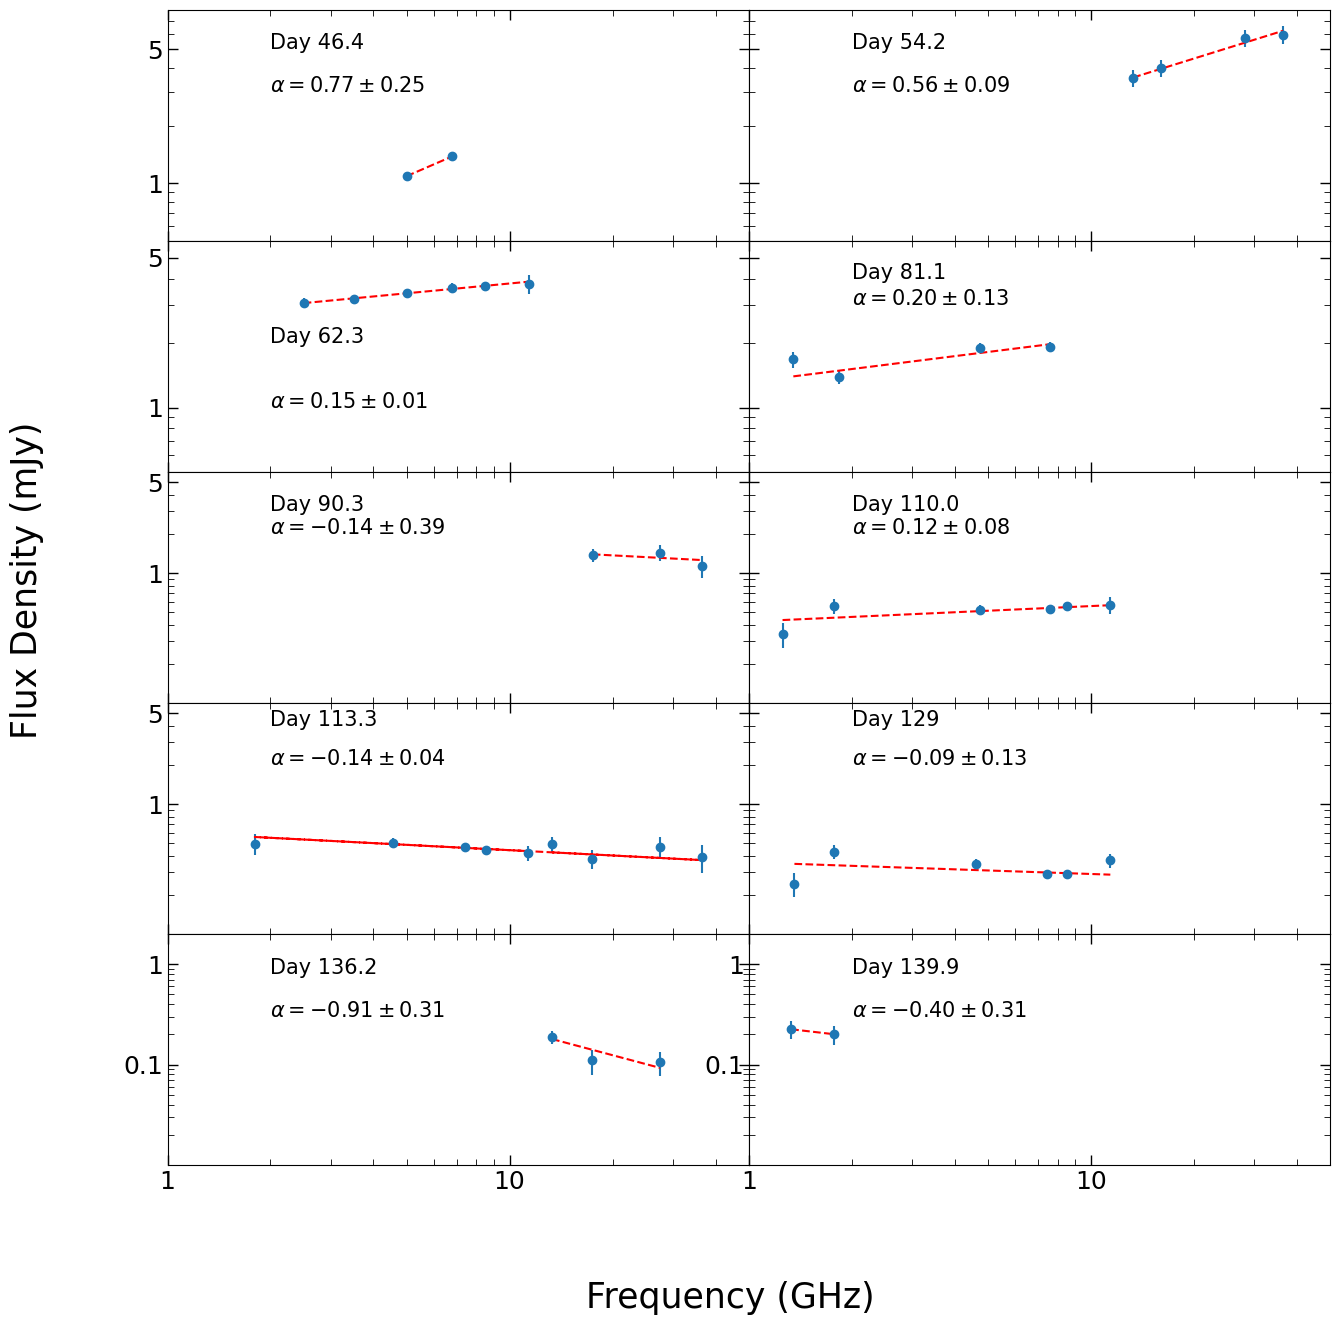

In [93]:
fig, axs = plt.subplots(5, 2, figsize=(15, 15), sharey=False, sharex = True)


axs[0,0].errorbar(freq_3, flux_3, yerr=quad_3, fmt='o')
axs[0,0].plot(freq_3, fit_model_weights3(freq_3), color='red', linestyle='--')

axs[0,0].set_xscale('log')
axs[0,0].set_yscale('log')

axs[0,0].annotate(r'${\alpha = 0.77 \pm 0.25}$', xy=(2, 3), fontsize=15)
axs[0,0].annotate('Day 46.4', xy=(2, 5), fontsize=15)


axs[0,0].set_yticks([1,5],labels=['1','5'], fontsize = 18)
axs[0,0].set_ylim([0.5,8])

axs[0,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0,0].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[0,1].errorbar(freq_4,flux_4, yerr=quad_4, fmt='o')
axs[0,1].plot(freq_4, fit_model_weights4(freq_4), color='red', linestyle='--')

axs[0,1].set_xscale('log')
axs[0,1].set_yscale('log')

axs[0,1].annotate(r'${\alpha = 0.56 \pm 0.09}$', xy=(2, 3), fontsize=15)
axs[0,1].annotate('Day 54.2', xy=(2, 5), fontsize=15)


axs[0,1].set_yticks([1,5],labels=['1','5'], fontsize = 18)
axs[0,1].set_ylim([0.5,8])

axs[0,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0,1].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=False, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[1,0].errorbar(freq_5, flux_5, yerr=quad_5, fmt='o')
axs[1,0].plot(freq_5, fit_model_weights5(freq_5), color='red', linestyle='--')

axs[1,0].set_xscale('log')
axs[1,0].set_yscale('log')

axs[1,0].annotate('Day 62.3', xy=(2, 2),fontsize=15)
axs[1,0].annotate(r'${\alpha = 0.15 \pm 0.01}$', xy=(2, 1),fontsize=15)

axs[1,0].set_yticks([1,5],labels=['1','5'], fontsize = 18)
axs[1,0].set_ylim([0.5,6])


axs[1,0].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1,0].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[1,1].errorbar(freq_7, flux_7, yerr=quad_7, fmt='o')
axs[1,1].plot(freq_7, fit_model_weights7(freq_7), color='red', linestyle='--')

axs[1,1].set_xscale('log')
axs[1,1].set_yscale('log')

axs[1,1].annotate(r'${\alpha = 0.20 \pm 0.13}$', xy=(2, 3),fontsize=15)
axs[1,1].annotate('Day 81.1', xy=(2, 4),fontsize=15)


axs[1,1].set_yticks([1,5], labels=['1', '5'], fontsize = 18)
axs[1,1].set_ylim([0.5,6])


axs[1,1].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1,1].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=False, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#######################################################
axs[2,0].errorbar(freq_8, flux_8, yerr=quad_8, fmt='o')
axs[2,0].plot(freq_8, fit_model_weights8(freq_8), color='red', linestyle='--')

axs[2,0].set_xscale('log')
axs[2,0].set_yscale('log')

axs[2,0].annotate(r'${\alpha = -0.14 \pm 0.39}$', xy=(2, 2), fontsize=15)
axs[2,0].annotate('Day 90.3', xy=(2, 3), fontsize=15)


axs[2,0].set_yticks([1, 5], labels=['1', '5'], fontsize = 18)
axs[2,0].set_ylim([0.1,6])

axs[2,0].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2,0].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[2,1].errorbar(freq_9, flux_9, yerr=quad_9, fmt='o')
axs[2,1].plot(freq_9, fit_model_weights9(freq_9), color='red', linestyle='--')

axs[2,1].set_xscale('log')
axs[2,1].set_yscale('log')


axs[2,1].annotate(r'${\alpha = 0.12 \pm 0.08}$', xy=(2, 2), fontsize=15)
axs[2,1].annotate('Day 110.0', xy=(2, 3), fontsize=15)


axs[2,1].set_yticks([1, 5], labels=['1', '5'], fontsize = 18)
axs[2,1].set_ylim([0.1,6])

axs[2,1].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2,1].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=False, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[3,0].errorbar(freq_10, flux_10, yerr=quad_10, fmt='o')
axs[3,0].plot(freq_10, fit_model_weights10(freq_10), color='red', linestyle='--')

axs[3,0].set_xscale('log')
axs[3,0].set_yscale('log')


axs[3,0].annotate(r'${\alpha = -0.14 \pm 0.04}$', xy=(2, 2), fontsize=15)
axs[3,0].annotate('Day 113.3', xy=(2, 4), fontsize=15)



axs[3,0].set_yticks([1, 5], labels=['1', '5'], fontsize = 18)
axs[3,0].set_ylim([0.1,6])

axs[3,0].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[3,0].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[3,1].errorbar(freq_11, flux_11, yerr=quad_11, fmt='o')
axs[3,1].plot(freq_11, fit_model_weights11(freq_11), color='red', linestyle='--')

axs[3,1].set_xscale('log')
axs[3,1].set_yscale('log')


axs[3,1].annotate(r'${\alpha = -0.09 \pm 0.13}$', xy=(2, 2), fontsize=15)
axs[3,1].annotate('Day 129', xy=(2, 4), fontsize=15)



axs[3,1].set_yticks([1, 5], labels=['1', '5'], fontsize = 18)
axs[3,1].set_ylim([0.1,6])

axs[3,1].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[3,1].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=False, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#######################################################
axs[4,0].errorbar(freq_12, flux_12, yerr=quad_12, fmt='o')
axs[4,0].plot(freq_12, fit_model_weights12(freq_12), color='red', linestyle='--')

axs[4,0].set_xscale('log')
axs[4,0].set_yscale('log')


axs[4,0].annotate(r'${\alpha = -0.91 \pm 0.31}$', xy=(2, 0.3), fontsize=15)
axs[4,0].annotate('Day 136.2', xy=(2, 0.8), fontsize=15)

axs[4,0].set_xticks([1, 10], labels=['1', '10'], fontsize = 18)
axs[4,0].set_xlim([1,50])

axs[4,0].set_yticks([0.1, 1], labels=['0.1', '1'], fontsize = 18)
axs[4,0].set_ylim([0.01,2])

axs[4,0].tick_params(which='minor', length =4, direction = 'in', left=True, top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[4,0].tick_params(which='major', length=7, direction = 'in', width =1, left = True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


#######################################################
axs[4,1].errorbar(freq_13, flux_13, yerr=quad_13, fmt='o')
axs[4,1].plot(freq_13, fit_model_weights13(freq_13), color='red', linestyle='--')

axs[4,1].set_xscale('log')
axs[4,1].set_yscale('log')


axs[4,1].annotate(r'${\alpha = -0.40 \pm 0.31}$', xy=(2, 0.3), fontsize=15)
axs[4,1].annotate('Day 139.9', xy=(2, 0.8), fontsize=15)


axs[4,1].set_xticks([1, 10], labels=['1', '10'], fontsize = 18)
axs[4,1].set_xlim([1,50])

axs[4,1].set_yticks([0.1, 1], labels=['0.1', '1'], fontsize = 18)
axs[4,1].set_ylim([0.01,2])


axs[4,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[4,1].tick_params(which='major', length=7, direction = 'in', width =1, left=True, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


fig.supxlabel("Frequency (GHz)", fontsize = 25)
fig.supylabel("Flux Density (mJy)", fontsize =25)
plt.subplots_adjust(wspace=0, hspace=0)
plt.savefig("V5589_SI.png")

plt.show();

